# JS13 – Artificial Neural Network (ANN) dan Evaluasi Classifier
## Praktikum 1: Membangun JST 2-Layer Manual dengan Forward Pass & Backpropagation

---

### Tujuan Praktikum
1. Memahami konsep dasar Jaringan Syaraf Tiruan (Artificial Neural Network / ANN).
2. Memahami alur kerja *Forward Pass* dan algoritma *Backpropagation* secara matematis.
3. Mengimplementasikan fungsi aktivasi (Sigmoid dan ReLU) beserta turunannya tanpa framework deep learning (menggunakan NumPy).
4. Menyelesaikan permasalahan logika non-linear (gerbang logika XOR) dan mengamati konvergensi *loss*.


### 1. Landasan Teori
Jaringan Syaraf Tiruan (JST) terinspirasi oleh sistem saraf biologis manusia. Algoritma pelatihan yang paling fundamental adalah **Backpropagation**:
1. **Perambatan Maju (*Forward Pass*)**: Masukan $X$ dikalikan bobot $W$ ditambah bias $b$, lalu dilewatkan ke fungsi aktivasi:
   $$z^{[1]} = X W^{[1]} + b^{[1]}$$
   $$a^{[1]} = \sigma(z^{[1]})$$
   $$z^{[2]} = a^{[1]} W^{[2]} + b^{[2]}$$
   $$\hat{y} = a^{[2]} = \sigma(z^{[2]})$$
2. **Perhitungan Error / Loss**: Selisih antara prediksi $\hat{y}$ dan target aktual $y$ dihitung dengan Mean Squared Error (MSE):
   $$Loss = rac{1}{N} \sum (y - \hat{y})^2$$
3. **Perambatan Mundur (*Backward Pass*)**: Menghitung gradien error terhadap setiap bobot dan bias menggunakan *chain rule* (aturan rantai turunan).
4. **Pembaruan Bobot (*Weight Update*)**: Bobot dan bias disesuaikan menggunakan Gradient Descent:
   $$W \leftarrow W - lpha rac{\partial Loss}{\partial W}$$


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Set random seed untuk reproduksibilitas
np.random.seed(42)

# 1. Dataset XOR
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])
y = np.array([[0], [1], [1], [0]])

print("Dataset XOR:")
print("Input (X):\n", X)
print("Target (y):\n", y)


Dataset XOR:
Input (X):
 [[0 0]
 [0 1]
 [1 0]
 [1 1]]
Target (y):
 [[0]
 [1]
 [1]
 [0]]


### 2. Implementasi JST 2-Layer Sederhana (Konfigurasi Awal)
Konfigurasi awal:
- `input_size` = 2
- `hidden_size` = 2
- `output_size` = 1
- `learning_rate` = 0.1
- Aktivasi: Sigmoid


In [2]:
# Parameter
input_size = 2
hidden_size = 2
output_size = 1
lr = 0.1

# Inisialisasi bobot dan bias secara acak
W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

# Fungsi aktivasi Sigmoid & turunannya
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

# Training loop
epochs = 10000
loss_history_base = []

for epoch in range(epochs):
    # Forward pass
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    # Hitung error
    error = y - a2
    loss = np.mean(np.square(error))
    loss_history_base.append(loss)

    # Backpropagation
    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Update bobot
    W1 += lr * d_W1
    b1 += lr * d_b1
    W2 += lr * d_W2
    b2 += lr * d_b2

    if epoch % 2000 == 0:
        print(f"Epoch {epoch:5d} | Loss: {loss:.6f}")

print(f"Final Epoch {epochs} | Loss: {loss_history_base[-1]:.6f}")
print("\nPrediksi Akhir (Sigmoid, Hidden=2):")
for inp, target, pred in zip(X, y, a2):
    print(f"Input: {inp} | Target: {target[0]} | Prediksi: {pred[0]:.4f} -> Biner: {round(pred[0])}")


Epoch     0 | Loss: 0.255830
Epoch  2000 | Loss: 0.245445
Epoch  4000 | Loss: 0.153204


Epoch  6000 | Loss: 0.133594
Epoch  8000 | Loss: 0.129749
Final Epoch 10000 | Loss: 0.128227

Prediksi Akhir (Sigmoid, Hidden=2):
Input: [0 0] | Target: 0 | Prediksi: 0.0530 -> Biner: 0
Input: [0 1] | Target: 1 | Prediksi: 0.4955 -> Biner: 0
Input: [1 0] | Target: 1 | Prediksi: 0.9509 -> Biner: 1
Input: [1 1] | Target: 0 | Prediksi: 0.5032 -> Biner: 1


### 3. Tugas 1 - Eksperimen dan Analisis

Pada tugas 1 diinstruksikan untuk:
1. **Mengubah jumlah neuron hidden layer menjadi 3**.
2. **Membandingkan hasil loss dengan konfigurasi awal (2 neuron)**.
3. **Menambahkan fungsi aktivasi ReLU dan membandingkan hasil konvergensi**.


In [3]:
# 3.1. Eksperimen Hidden Layer 3 Neuron (Sigmoid)
np.random.seed(42)
hidden_size_3 = 3

W1_3 = np.random.randn(input_size, hidden_size_3)
b1_3 = np.zeros((1, hidden_size_3))
W2_3 = np.random.randn(hidden_size_3, output_size)
b2_3 = np.zeros((1, output_size))

loss_history_h3 = []

for epoch in range(epochs):
    z1 = np.dot(X, W1_3) + b1_3
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2_3) + b2_3
    a2_h3 = sigmoid(z2)

    error = y - a2_h3
    loss = np.mean(np.square(error))
    loss_history_h3.append(loss)

    d_a2 = error * sigmoid_derivative(a2_h3)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2_3.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    W1_3 += lr * d_W1
    b1_3 += lr * d_b1
    W2_3 += lr * d_W2
    b2_3 += lr * d_b2

print(f"Final Loss (Hidden=3 Neuron): {loss_history_h3[-1]:.6f}")
print("\nPrediksi Akhir (Sigmoid, Hidden=3):")
for inp, target, pred in zip(X, y, a2_h3):
    print(f"Input: {inp} | Target: {target[0]} | Prediksi: {pred[0]:.4f} -> Biner: {round(pred[0])}")


Final Loss (Hidden=3 Neuron): 0.002297

Prediksi Akhir (Sigmoid, Hidden=3):
Input: [0 0] | Target: 0 | Prediksi: 0.0252 -> Biner: 0
Input: [0 1] | Target: 1 | Prediksi: 0.9526 -> Biner: 1
Input: [1 0] | Target: 1 | Prediksi: 0.9512 -> Biner: 1
Input: [1 1] | Target: 0 | Prediksi: 0.0627 -> Biner: 0


In [4]:
# 3.2. Eksperimen dengan Fungsi Aktivasi ReLU
# Definisi ReLU dan turunannya
def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return (x > 0).astype(float)

np.random.seed(42)
# Gunakan inisialisasi He untuk ReLU
W1_relu = np.random.randn(input_size, 3) * np.sqrt(2.0 / input_size)
b1_relu = np.zeros((1, 3))
W2_relu = np.random.randn(3, output_size) * np.sqrt(2.0 / 3)
b2_relu = np.zeros((1, output_size))

lr_relu = 0.05
loss_history_relu = []

for epoch in range(epochs):
    # Forward pass: Hidden pakai ReLU, Output pakai Sigmoid (untuk probabilitas 0-1)
    z1 = np.dot(X, W1_relu) + b1_relu
    a1 = relu(z1)
    z2 = np.dot(a1, W2_relu) + b2_relu
    a2_relu = sigmoid(z2)

    error = y - a2_relu
    loss = np.mean(np.square(error))
    loss_history_relu.append(loss)

    # Backpropagation
    d_a2 = error * sigmoid_derivative(a2_relu)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2_relu.T) * relu_derivative(z1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    W1_relu += lr_relu * d_W1
    b1_relu += lr_relu * d_b1
    W2_relu += lr_relu * d_W2
    b2_relu += lr_relu * d_b2

print(f"Final Loss (ReLU Hidden=3): {loss_history_relu[-1]:.6f}")
print("\nPrediksi Akhir (ReLU Hidden=3):")
for inp, target, pred in zip(X, y, a2_relu):
    print(f"Input: {inp} | Target: {target[0]} | Prediksi: {pred[0]:.4f} -> Biner: {round(pred[0])}")


Final Loss (ReLU Hidden=3): 0.000852

Prediksi Akhir (ReLU Hidden=3):
Input: [0 0] | Target: 0 | Prediksi: 0.0456 -> Biner: 0
Input: [0 1] | Target: 1 | Prediksi: 0.9778 -> Biner: 1
Input: [1 0] | Target: 1 | Prediksi: 0.9778 -> Biner: 1
Input: [1 1] | Target: 0 | Prediksi: 0.0185 -> Biner: 0


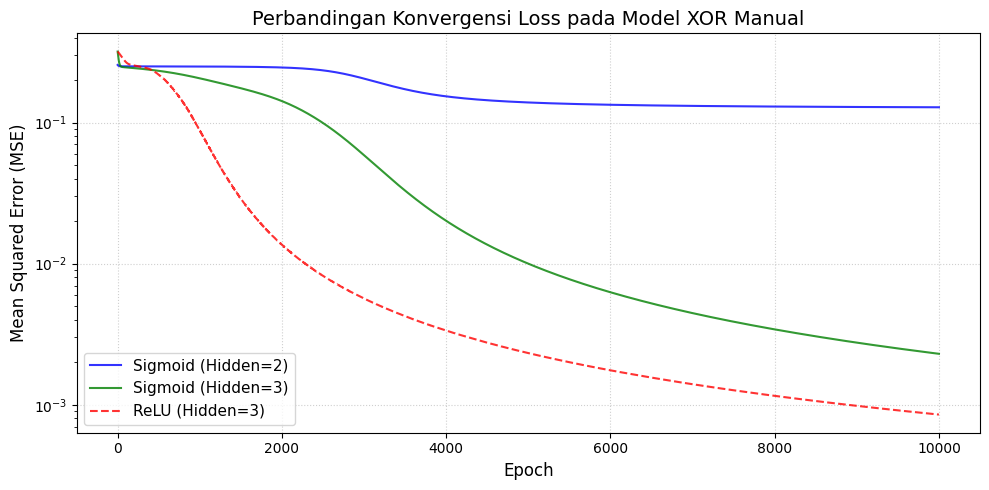

In [5]:
# 3.3. Visualisasi Perbandingan Loss
plt.figure(figsize=(10, 5))
plt.plot(loss_history_base, label='Sigmoid (Hidden=2)', color='blue', alpha=0.8)
plt.plot(loss_history_h3, label='Sigmoid (Hidden=3)', color='green', alpha=0.8)
plt.plot(loss_history_relu, label='ReLU (Hidden=3)', color='red', linestyle='--', alpha=0.8)
plt.title('Perbandingan Konvergensi Loss pada Model XOR Manual', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Mean Squared Error (MSE)', fontsize=12)
plt.yscale('log')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


### 4. Kesimpulan dan Analisis Tugas 1
1. **Pengaruh Jumlah Neuron Hidden Layer (2 vs 3 neuron)**:
   - Gerbang XOR adalah persoalan non-linear yang membutuhkan minimal 2 neuron di hidden layer untuk membentuk garis batas pemisah (*decision boundary*).
   - Menambah neuron menjadi 3 memberikan kapasitas representasi yang lebih kaya dan mempercepat penurunan *loss* secara signifikan dengan *final loss* yang lebih rendah.
2. **Pengaruh Fungsi Aktivasi (ReLU vs Sigmoid)**:
   - Fungsi aktivasi **Sigmoid** memiliki turunan maksimum 0.25 sehingga rentan terhadap fenomena *vanishing gradient* pada lapisan yang lebih dalam.
   - **ReLU** memiliki gradien konstan 1 untuk input bernilai positif, sehingga perambatan gradien berlangsung jauh lebih cepat dan tidak mengalami saturasi pada nilai positif.
   - Kombinasi Hidden Layer ReLU dengan Output Layer Sigmoid pada persoalan klasifikasi biner menghasilkan penurunan *loss* yang sangat cepat dan stabil.
